# Evaluation Homework

### Data Preparation

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("data/course_lead_scoring.csv")

In [ ]:
# df.describe()

In [ ]:
# df.head()

In [ ]:
# num_cols = df.select_dtypes(include=[np.number]).columns
num_cols = list(df.dtypes[df.dtypes != 'object'].index)
df[num_cols] = df[num_cols].fillna(0.0)

cat_cols = list(df.dtypes[df.dtypes == 'object'].index)
df[cat_cols] = df[cat_cols].fillna('NA')

# print(df.isna().sum())

df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [ ]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)


In [ ]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

num_cols.remove('converted')


#### Q1: ROC AUC Feature Importnace

In [ ]:
auc_scores = {}
for c in num_cols:
  auc = roc_auc_score(y_train, df_train[c])
  if auc < 0.5:
    auc = roc_auc_score(y_train, -df_train[c])

  auc_scores[c] = max(auc, -auc)

auc_scores


{'annual_income': np.float64(0.6081977776250831),
 'number_of_courses_viewed': np.float64(0.7229894623989618),
 'interaction_count': np.float64(0.7649203047563227),
 'lead_score': np.float64(0.7882254810906102)}

- The numerical variable with the highest AUC is "lead_score"

#### Q2: Training the model

In [ ]:
def train(df_train, y_train, C=1.0):
  dv = DictVectorizer(sparse=False)

  train_dict = df_train[num_cols + cat_cols].to_dict(orient='records')
  X_train = dv.fit_transform(train_dict)

  model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
  model.fit(X_train, y_train)

  return (dv, model)

dv, model = train(df_train, y_train)

In [ ]:
def predict(df, dv, model):
  val_dict = df[num_cols + cat_cols].to_dict(orient='records')
  X_val = dv.transform(val_dict)

  y_pred = model.predict_proba(X_val)[:,1]

  return y_pred

y_pred = predict(df_val, dv, model)

In [ ]:
auc = roc_auc_score(y_val, y_pred)
round(auc, 3)

np.float64(0.732)

The AUC of this model on the validation dataset is "0.732"

#### Q3: Precision and Recall

In [ ]:
thresholds = np.arange(0, 1, 0.01)

scores = []

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores.append((t, tp, fp, fn, tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)
df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)

df_scores.head()

,threshold,tp,fp,fn,tn,precision,recall
0,0.00,586,414,0,0,0.586,1.0
1,0.01,586,414,0,0,0.586,1.0
2,0.02,586,414,0,0,0.586,1.0
3,0.03,586,414,0,0,0.586,1.0
4,0.04,586,414,0,0,0.586,1.0


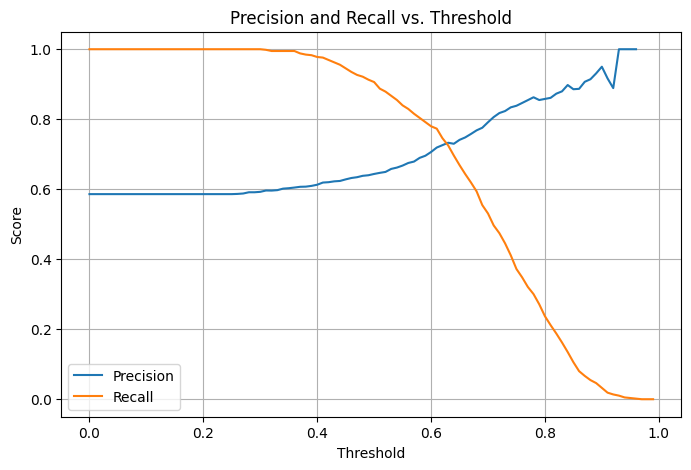

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(df_scores.threshold, df_scores['precision'], label='Precision')
plt.plot(df_scores.threshold, df_scores['recall'], label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs. Threshold')
plt.grid(True)
plt.legend()
plt.show()

- The threshold precision and recall curves intersect is "0.63"

#### Q4: F1 score

In [ ]:
df_scores['f1'] = 2 * ((df_scores['precision'] * df_scores['recall']) / (df_scores['precision'] + df_scores['recall']))

df_scores['f1'].iloc[df_scores['f1'].idxmax()]

np.float64(0.7576158940397352)

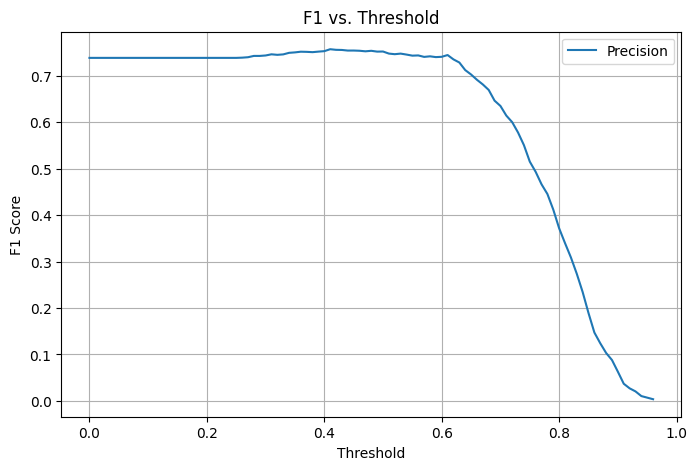

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(df_scores.threshold, df_scores['f1'], label='Precision')
plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.title('F1 vs. Threshold')
plt.grid(True)
plt.legend()
plt.show()

- The threshold at which F1 is maximal is "0.41"

#### Q5: 5-Fold CV

In [ ]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

scores_np = np.array(scores)
round(scores_np.std(), 3)

np.float64(0.007)

- The standard deviation of the scores across different folds is "0.007"

#### Q6: Hyperparameter Tuning

In [ ]:
Cs = [0.000001, 0.001, 1]
results = {}
scores = []

for C in Cs:
  for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

  result = {"mean": round(np.mean(scores), 3), "std": round(np.std(scores), 3)}
  results[C] =  result


results

{1e-06: {'mean': np.float64(0.617), 'std': np.float64(0.019)},
 0.001: {'mean': np.float64(0.683), 'std': np.float64(0.068)},
 1: {'mean': np.float64(0.699), 'std': np.float64(0.06)}}

- The C leads to the best mean ROC AUC is "1"